In [41]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [42]:
from common import *

compute = True

In [43]:
from mg_sampling.motifs import IonNucleicAnalysis
from mg_sampling.motifs import summarize_motifs, compress_motifs

replicates = range(3)
system = "1naj"
forcefield = "mMg_tip3p"

motif_count, motif_info = {}, {}
time_weight = {}
for rep in replicates:
    path = PROJECT_DIR / "biased_md" / system / forcefield / f"rep{rep:02d}"
    filepath = path / "MG_motifs.parquet"
    if filepath.exists() and not compute:
        df = pd.read_parquet(filepath)
    else:
        u = mda.Universe(path / "input.gro", path / "run.xtc")
        anal = IonNucleicAnalysis(u, "name MG", "nucleic", inner_cutoff=2.8, outer_cutoff=5).run(n_workers=4, backend="dask")
        df = anal.to_pandas().assign(replicate=rep)
        df.to_parquet(filepath)

    # frame bias for later weight calculation
    cv = read_plumed(path / "bias.COLVAR")
    cv["time"] = cv["time"].round()
    time = df["time"].unique()
    bias = cv.set_index("time").loc[time, "bias.bias"]
    weight = np.exp(bias / RT)
    time_weight[rep] = weight
    count, info = compress_motifs(df)
    motif_count[rep] = count
    motif_info[rep] = info


100%|██████████| 1000/1000 [00:04<00:00, 228.29it/s]


In [45]:
def split_tuple_series(s: pd.Series, columns: list[str] | None = None):
    return pd.DataFrame(s.to_list(), index=s.index, columns=columns)

# Compute error using bayesian bootstrap on block
from mg_sampling.stats import bayesian_bootstrap, bootstrap

complete_index = pd.MultiIndex.from_product(motif_summary.index.levels)
p = motif_summary["occupancy"].reindex(complete_index, fill_value=0.0)
p_mean = p.groupby(["name", "motif"]).agg(p_mean="mean")
p_ci = split_tuple_series(
    p.groupby(["name", "motif"]).agg(ci=lambda xs: bayesian_bootstrap(xs, np.average, weights=block_weights, confidence_level=0.95).confidence_interval)["ci"],
    columns=["p_low", "p_high"],
)
p_ci = split_tuple_series(
    p.groupby(["name", "motif"]).agg(ci=lambda xs: bootstrap(xs, np.average, weights=block_weights, confidence_level=0.95).confidence_interval)["ci"],
    columns=["p_low", "p_high"],
)
motif_info = motif_summary[["n_inner", "inner_names", "inner_resids", "inner_resnames"]].groupby(["name", "motif"]).first()
p = pd.concat([p_mean, p_ci, motif_info], axis=1)

In [46]:
data = p.query("n_inner == 1").explode(["inner_names", "inner_resids", "inner_resnames"]).sort_values(["inner_resids", "inner_names"])

In [47]:
resids = list(range(1, 25))
sequence = list("CGCGAATTCGCG")

/tmp/ipykernel_936323/3513962777.py:60: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(sequence)


(0.0, 0.12)

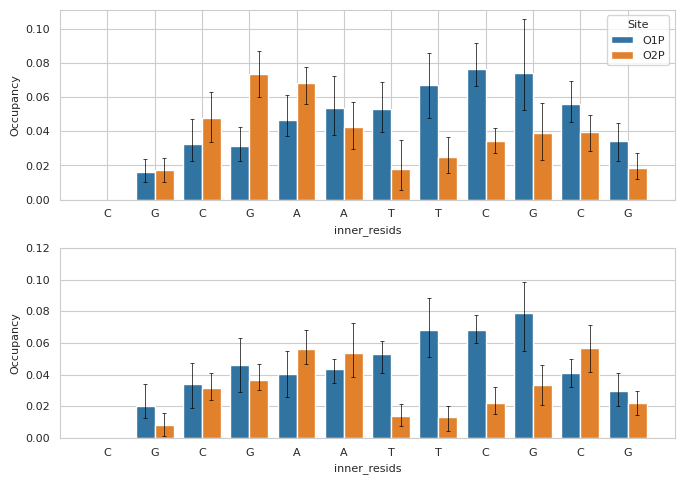

In [48]:
fig, (ax1, ax2) = plt.subplots(nrows=2, figsize=(17.1*cm, 12*cm))

ax1 = sns.barplot(
    data=data.query("inner_resids <= 12"),
    x='inner_resids',
    native_scale=True,
    y='p_mean',
    hue='inner_names',
    ax=ax1,
)
handles, labels = ax1.get_legend_handles_labels()
ax1.legend(handles, labels, title="Site")

for i, (name, group) in enumerate(data.query("inner_resids <= 12").groupby('inner_names')):
    container = ax1.containers[i]
    x_coords = [rect.get_x() + rect.get_width() / 2 for rect in container]
    yerr = (group['p_mean'] - group["p_low"], group["p_high"] - group['p_mean'])
    ax1.errorbar(
        y=group['p_mean'],
        x=x_coords,
        yerr=yerr,
        ls='none',
        c='black',
        capsize=1.5,
        elinewidth=0.5,
        capthick=0.5,
    )

ax1.set_ylabel("Occupancy")
ax1.set_xticks(resids[:12], sequence[:12])
ax1.set_xlim(0, 13)
ax2.set_ylim(0, 0.12)

ax2 = sns.barplot(
    data=data.query("inner_resids > 12"),
    x='inner_resids',
    y='p_mean',
    hue='inner_names',
    ax=ax2,
    order=resids[12:],
    legend=False,
)

for i, (name, group) in enumerate(data.query("inner_resids > 12").groupby('inner_names')):
    container = ax2.containers[i]
    x_coords = [rect.get_x() + rect.get_width() / 2 for rect in container]
    yerr = (group['p_mean'] - group["p_low"], group["p_high"] - group['p_mean'])
    ax2.errorbar(
        y=group['p_mean'],
        x=x_coords,
        yerr=yerr,
        ls='none',
        c='black',
        capsize=1.5,
        elinewidth=0.5,
        capthick=0.5,
    )

ax2.set_ylabel("Occupancy")
ax2.set_xticklabels(sequence)
ax2.set_xlim(-1, 12)
ax2.set_ylim(0, 0.12)


In [49]:
data.set_index(["inner_resids", "inner_names"]).loc[:13, :]

p_mean     p_low    p_high  n_inner inner_resnames
inner_resids inner_names                                                      
2            O1P          0.015945  0.010209  0.023633        1             DG
             O2P          0.017290  0.010543  0.024335        1             DG
3            O1P          0.032365  0.022286  0.047076        1             DC
             O2P          0.047588  0.033462  0.062815        1             DC
4            O1P          0.031259  0.022601  0.042294        1             DG
             O2P          0.073472  0.059843  0.086903        1             DG
5            O1P          0.046624  0.036928  0.061455        1             DA
             O2P          0.068154  0.055705  0.077482        1             DA
6            O1P          0.053683  0.037867  0.072216        1             DA
             O2P          0.042317  0.029346  0.057130        1             DA
7            O1P          0.052859  0.039355  0.068860        1             DT
             O2P          0.017826  0.005343  0.034718        1             DT
8            O1P          0.067000  0.047735  0.085506        1             DT
             O2P          0.024939  0.015352  0.036598        1             DT
9            O1P          0.076246  0.066714  0.091325        1             DC
             O2P          0.034235  0.027267  0.041590        1             DC
10           O1P          0.074052  0.052414  0.105682        1             DG
             O2P          0.039087  0.023401  0.056271        1             DG
11           O1P          0.056055  0.045242  0.069382        1             DC
             O2P          0.039427  0.028304  0.049291        1             DC
12           O1P          0.033985  0.022395  0.044701        1             DG
             O2P          0.018630  0.012016  0.027167        1             DG

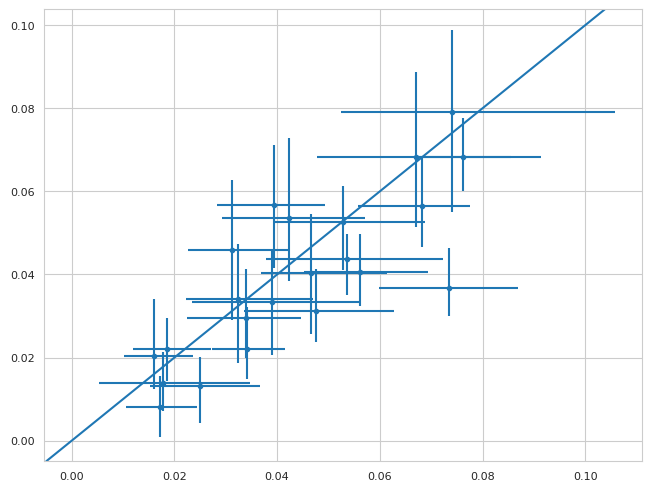

In [50]:

plt.errorbar(
    data.set_index(["inner_resids", "inner_names"]).loc[:13, :]["p_mean"],
    data.set_index(["inner_resids", "inner_names"]).loc[13:, :]["p_mean"],  
    xerr = (
        data.set_index(["inner_resids", "inner_names"]).loc[:13, :]["p_mean"]
        - data.set_index(["inner_resids", "inner_names"]).loc[:13, :]["p_low"],
        data.set_index(["inner_resids", "inner_names"]).loc[:13, :]["p_high"]
        - data.set_index(["inner_resids", "inner_names"]).loc[:13, :]["p_mean"],
    ),
    yerr = (
        data.set_index(["inner_resids", "inner_names"]).loc[13:, :]["p_mean"]
        - data.set_index(["inner_resids", "inner_names"]).loc[13:, :]["p_low"],
        data.set_index(["inner_resids", "inner_names"]).loc[13:, :]["p_high"]
        - data.set_index(["inner_resids", "inner_names"]).loc[13:, :]["p_mean"],
    ),
    linestyle="none",
    marker=".",
)
plt.axline((0,0), slope=1)